# Addis February: Dry or Belg? Calendar sensitivity of the Addis calibration results (28 Oct 2026)

The seasonality audit (28 Oct) recommends the Ethiopian Meteorological Institute calendar for new
Addis reporting: Bega Oct–Jan, Belg Feb–May, Kiremt Jun–Sep (`belg_feb`). Every frozen calibration
result so far was binned with February in Dry: Dry Oct–Feb, Belg Mar–May, Kiremt Jun–Sep (`dry_feb`).

This notebook moves February between the two and asks **whether any seasonal calibration result
changes**. The cohort, exclusions, estimator and validation design stay the same; only February moves.

- **Cohort:** the poster's 189 Addis filters that have a published SPARTAN FTIR EC (`run_meeting_20261028.load`).
- **Estimator:** Deming FTIR EC against HIPS Fabs/MAC with the poster's λ (σx from HIPS uncertainty, σy 0.531),
  plus 1,000-sample bootstrap 95% intervals.
- **Calibrations that do not use season** (one model for every filter): SPARTAN published, the all-IMPROVE
  baseline-corrected model (Figure 7), and the 500 lowest-TOR-OC/EC IMPROVE filters (28 Oct item 1).
  For these, changing the calendar only regroups the same predictions.
- **The calibration that does use season**, Figure 9's season-specific spectral look-alikes. Each season
  takes the 500 IMPROVE filters most correlated with that season's median Addis spectrum. Under `belg_feb`,
  the Dry/Bega and Belg sets are reselected and refitted with the same recipe. Kiremt's months do not
  change, so its model must come out identical.

Outputs go to `output/tables/addis_feb_sensitivity_20261028/`.

## Result (28 Oct 2026)

**Moving February matters for one result only: Figure 9's season-specific Belg calibration.** The
models that do not use season are unchanged within their intervals.

| | dry_feb | belg_feb |
|---|---|---|
| Filters Dry/Bega · Belg · Kiremt | 73 · 51 · 65 | 55 · 69 · 65 |
| Figure 9 Belg: Deming slope (95% CI) | 0.32 (0.15–0.47) | **0.67 (0.56–0.79)** |
| Figure 9 Belg: intercept · R² | +1.06 · 0.22 | −1.38 · 0.75 |
| Figure 9 Dry/Bega: slope | 0.35 (0.27–0.44) | 0.32 (0.22–0.41) |
| Figure 9 Kiremt | 0.94 | 0.94 (identical model) |
| 500 lowest TOR OC/EC, Belg: slope | 0.72 | 0.72 |
| All IMPROVE (Figure 7) and SPARTAN published, any season | change ≤ 0.05 in slope | |

- **It is the look-alike set, not PLS k** (§5b). The `belg_feb` Belg target spectrum includes the 18 February
  filters, so only 315 of the 500 IMPROVE look-alikes stay the same. At every k from 3 to 20, the new set
  gives a Belg slope of about 0.6–0.8 and the old set about 0.2–0.5. Scoring on either calendar's Belg filters
  makes almost no difference. Cross-validation also picks a lower k (13 to 4), but at a fixed k the gap between
  the sets stays.
- **What this does to the 28 Oct findings.** "The lowest-OC/EC set fixes most of Belg (0.32 to 0.72)" is a
  `dry_feb` statement. Under `belg_feb`, the spectral look-alikes already give 0.67, so OC/EC selection adds little
  for Belg. Dry/Bega's failure (slope about 0.3 under every calibration but SPARTAN's) holds under both. The
  organic-signal correlation within Dry/Bega holds (partial ρ 0.46 to 0.53). **Within Belg it does not**: organic-index partial ρ
  goes from 0.63 to 0.13 for Figure 9 and from 0.51 to 0.28 for Figure 7, so "the Belg error tracks the organic signal" depends on
  February.
- **The season-specific look-alike method is fragile.** One month of spectra moves more than a third of the
  selection and doubles the slope. Read that as an instability of selecting by median-spectrum correlation, not
  as evidence for either calendar. Choose the calendar on meteorological grounds (the audit recommends
  `belg_feb`, EMI and Shlipak et al. 2026), not on which one gives the better Belg fit.
- **Reporting.** Any seasonal Addis number from a season-specific calibration must name its calendar. A
  pooled calibration's seasonal readouts can be quoted under either calendar, with the counts above.

Tables: `output/tables/addis_feb_sensitivity_20261028/`. Figures: `output/plots/addis_feb_sensitivity_*.png`.

In [1]:
import sys
sys.path.insert(0, './scripts')
sys.path.insert(0, './workflows')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import resolve_seasons, season_for_month
from plotting import apply_default_style
import analog_bias as ab
import run_meeting_20261028 as rm

apply_default_style()
OUT = Path('output/tables/addis_feb_sensitivity_20261028')
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)

## 1. Load the poster's inputs (slow: about 10 minutes reading from Drive)

In [2]:
d = rm.load()
d['chem'] = rm.spartan_chem(d['A'])
rm.calibrations(d)          # asserts Figure 7: 0.59x - 1.21
A, ctx, lib, X = d['A'], d['ctx'], d['lib'], d['X']
hips, vol = A.hips.to_numpy(), A.vol.to_numpy()
month = pd.to_datetime(A.date).dt.month.to_numpy()

Filter dataset loaded: 44493 measurements
Sites: ['CHTS' 'ETAD' 'INDH' 'USPA']
Date range: 2013-06-28 to 2024-12-08


Addis 189 filters; IMPROVE library 12393; look-alikes 97; seasonal sets Dry 500, Belg 500, Kiremt 500


Filter dataset loaded: 44493 measurements
Sites: ['CHTS' 'ETAD' 'INDH' 'USPA']
Date range: 2013-06-28 to 2024-12-08


all-IMPROVE baseline-corrected calibration: k 8, Addis 0.59x -1.21


## 2. The two calendars on this cohort

In [3]:
# the evaluation table's season is the dry_feb calendar; check that, then add belg_feb
DRY = resolve_seasons('dry_feb'); BELG = resolve_seasons('belg_feb')
assert (A.season.to_numpy() == np.array([season_for_month(m, DRY) for m in month])).all()
# one short name per season so the two calendars line up: Dry/Bega, Belg, Kiremt
short = {'Dry (Oct-Feb)': 'Dry/Bega', 'Belg (Mar-May)': 'Belg', 'Kiremt (Jun-Sep)': 'Kiremt',
         'Bega (Oct-Jan, dry)': 'Dry/Bega', 'Belg (Feb-May, short rains)': 'Belg', 'Kiremt (Jun-Sep, long rains)': 'Kiremt'}
CAL = {'dry_feb': np.array([short[season_for_month(m, DRY)] for m in month]),
       'belg_feb': np.array([short[season_for_month(m, BELG)] for m in month])}
SEAS = ['Dry/Bega', 'Belg', 'Kiremt']
moved = CAL['dry_feb'] != CAL['belg_feb']
assert (month[moved] == 2).all() and moved.sum() == (month == 2).sum()

counts = pd.DataFrame({c: pd.Series(v).value_counts().reindex(SEAS) for c, v in CAL.items()})
counts.loc['total'] = counts.sum()
print(counts)
print()
print('February filters that move:', int(moved.sum()), 'by year', pd.Series(pd.to_datetime(A.date[moved]).dt.year).value_counts().sort_index().to_dict())
counts.to_csv(OUT / 'season_counts.csv')

          dry_feb  belg_feb
Dry/Bega       73        55
Belg           51        69
Kiremt         65        65
total         189       189

February filters that move: 18 by year {2023: 9, 2024: 9}


## 3. Season-specific look-alikes (Figure 9), refitted under each calendar

In [4]:
# Figure 9 chose each season's look-alikes from the median spectrum of *all* the run's Addis filters in that
# season (ctx.addis, 233), not only the 189 with a published SPARTAN EC, so classify those too
month_all = pd.to_datetime(ctx.addis.date).dt.month.to_numpy()
assert (ctx.addis.season.to_numpy() == np.array([season_for_month(m, DRY) for m in month_all])).all()
CAL_ALL = {'dry_feb': np.array([short[season_for_month(m, DRY)] for m in month_all]),
           'belg_feb': np.array([short[season_for_month(m, BELG)] for m in month_all])}
print('spectra choosing the look-alikes:', {c: pd.Series(v).value_counts().reindex(SEAS).to_dict() for c, v in CAL_ALL.items()})

def lookalike_predictions(c):
    """Figure 9's recipe: per season, the 500 IMPROVE filters closest to that season's median spectrum, refitted."""
    pred, members, ks = np.full(len(A), np.nan), {}, {}
    for s in SEAS:
        m = CAL[c] == s
        pos, _ = ab.correlation_analogs(ctx, 'AIRSpec', CAL_ALL[c] == s, ab.LOCKED_MASK)
        L = lib.iloc[pos]
        f = ab.fit_cohort(X[pos], L.y, L.Site)
        pred[m] = (f.predict(d['XA']) / vol)[m]
        members[s], ks[s] = set(L.filter_id), f.k
        SETS[(c, s)] = (pos, f.train)
    return pred, members, ks

SETS = {}   # (calendar, season) -> (look-alike positions, protocol train mask), for section 5b

look = {c: lookalike_predictions(c) for c in CAL}
# under dry_feb this must be Figure 9 itself
assert np.allclose(look['dry_feb'][0], A.pred_season.to_numpy(), atol=1e-6)
# Kiremt's months are the same in both calendars, so its model is too
k = CAL['dry_feb'] == 'Kiremt'
assert look['dry_feb'][1]['Kiremt'] == look['belg_feb'][1]['Kiremt']
assert np.allclose(look['dry_feb'][0][k], look['belg_feb'][0][k])

overlap = pd.DataFrame([{'season': s, 'k dry_feb': look['dry_feb'][2][s], 'k belg_feb': look['belg_feb'][2][s],
                         'look-alikes shared (of 500)': len(look['dry_feb'][1][s] & look['belg_feb'][1][s])} for s in SEAS])
overlap.to_csv(OUT / 'lookalike_overlap.csv', index=False)
overlap

spectra choosing the look-alikes: {'dry_feb': {'Dry/Bega': 102, 'Belg': 60, 'Kiremt': 71}, 'belg_feb': {'Dry/Bega': 81, 'Belg': 81, 'Kiremt': 71}}


,season,k dry_feb,k belg_feb,look-alikes shared (of 500)
0,Dry/Bega,17,7,435
1,Belg,13,4,315
2,Kiremt,16,16,500


## 4. Calibrations that do not use season: the lowest-OC/EC set (28 Oct item 1)

In [5]:
ok = ((lib.tor_ec_ugm3 > 0) & (lib.tor_oc_ugm3 > 0) & lib.tor_oc_ec.notna() & (lib.y >= 1)).to_numpy()
ocec = lib.tor_oc_ec.to_numpy()
lowest = np.flatnonzero(ok)[np.argsort(ocec[ok], kind='stable')][:rm.N]
f_low = ab.fit_cohort(X[lowest], lib.y.iloc[lowest], lib.Site.iloc[lowest])
pred_low = f_low.predict(d['XA']) / vol
print('lowest-OC/EC calibration: k', f_low.k)

lowest-OC/EC calibration: k 5


## 5. Deming FTIR vs HIPS by season, both calendars

In [6]:
CALIBRATIONS = {
    'season-specific look-alikes (Figure 9)': {c: look[c][0] for c in CAL},
    'SPARTAN published': {c: A.spartan.to_numpy() for c in CAL},
    'all IMPROVE (Figure 7)': {c: d['pred_one'] for c in CAL},
    '500 lowest TOR OC/EC': {c: pred_low for c in CAL},
}

def fit(x, y):
    st = ab.xy_stats(x, y, lam=ctx.lam, sigma_x=ctx.sigma_x, sigma_y=ab.SIGMA_Y_PROXY, boot=True)
    return {k: st.get(k) for k in ('n', 'deming_slope', 'slope_ci_low', 'slope_ci_high', 'deming_intercept',
                                    'intercept_ci_low', 'intercept_ci_high', 'R2', 'RMSE', 'bias')}

rows = []
for cal_name, by in CALIBRATIONS.items():
    for c, labels in CAL.items():
        for s in SEAS + ['All Addis']:
            m = np.ones(len(A), bool) if s == 'All Addis' else labels == s
            rows.append({'calibration': cal_name, 'calendar': c, 'season': s, **fit(hips[m], by[c][m])})
stats = pd.DataFrame(rows)
stats.to_csv(OUT / 'deming_by_season.csv', index=False)

wide = stats.pivot_table(index=['calibration', 'season'], columns='calendar',
                         values=['n', 'deming_slope', 'deming_intercept', 'R2', 'RMSE'], sort=False)
wide = wide.reindex(columns=['dry_feb', 'belg_feb'], level=1).round(2)
wide

n          deming_slope          deming_intercept               R2             RMSE         
calendar                                         dry_feb belg_feb      dry_feb belg_feb          dry_feb belg_feb dry_feb belg_feb dry_feb belg_feb
calibration                            season                                                                                                      
season-specific look-alikes (Figure 9) Dry/Bega     73.0     55.0         0.35     0.32            -0.29    -0.19    0.51     0.52    3.09     3.13
                                       Belg         51.0     69.0         0.32     0.67             1.06    -1.38    0.22     0.75    2.37     2.93
                                       Kiremt       65.0     65.0         0.94     0.94            -0.57    -0.57    0.67     0.67    1.10     1.10
                                       All Addis   189.0    189.0         1.51     1.59            -4.59    -5.16    0.55     0.59    2.37     2.53
SPARTAN published                      Dry/Bega     73.0     55.0         1.41     1.47            -2.62    -2.87    0.46     0.57    1.17     1.15
                                       Belg         51.0     69.0         1.89     1.92            -4.17    -4.41    0.73     0.66    1.08     1.12
                                       Kiremt       65.0     65.0         2.19     2.19            -5.09    -5.09    0.82     0.82    2.00     2.00
                                       All Addis   189.0    189.0         2.30     2.30            -6.09    -6.09    0.78     0.78    1.49     1.49
all IMPROVE (Figure 7)                 Dry/Bega     73.0     55.0         0.31     0.34            -0.17    -0.27    0.47     0.51    3.14     3.13
                                       Belg         51.0     69.0         0.49     0.47            -0.78    -0.77    0.76     0.72    3.30     3.26
                                       Kiremt       65.0     65.0         0.50     0.50            -0.48    -0.48    0.51     0.51    3.34     3.34
                                       All Addis   189.0    189.0         0.59     0.59            -1.21    -1.21    0.69     0.69    3.25     3.25
500 lowest TOR OC/EC                   Dry/Bega     73.0     55.0         0.50     0.53            -0.47    -0.62    0.43     0.48    2.67     2.68
                                       Belg         51.0     69.0         0.72     0.72            -1.16    -1.20    0.61     0.60    2.55     2.57
                                       Kiremt       65.0     65.0         0.75     0.75            -0.75    -0.75    0.41     0.41    2.32     2.32
                                       All Addis   189.0    189.0         0.92     0.92            -2.02    -2.02    0.63     0.63    2.52     2.52

In [7]:
# the bootstrap keys: check what xy_stats returned, so the intervals below are the right ones
print(sorted(k for k in stats.columns if k.endswith(('_low', '_high'))))
print(stats[['slope_ci_low', 'slope_ci_high']].notna().mean().to_dict())

['intercept_ci_high', 'intercept_ci_low', 'slope_ci_high', 'slope_ci_low']
{'slope_ci_low': 1.0, 'slope_ci_high': 1.0}


### Change from moving February (belg_feb minus dry_feb)

A change is only worth a sentence if it is large next to the bootstrap interval. The column
`slope change / dry_feb CI half-width` puts each change on that scale.

In [8]:
key = ['calibration', 'season']
a = stats[stats.calendar.eq('dry_feb')].set_index(key)
b = stats[stats.calendar.eq('belg_feb')].set_index(key)
delta = pd.DataFrame({
    'n dry_feb': a.n, 'n belg_feb': b.n,
    'slope dry_feb': a.deming_slope, 'slope belg_feb': b.deming_slope,
    'Δ slope': b.deming_slope - a.deming_slope,
    'Δ intercept': b.deming_intercept - a.deming_intercept,
    'Δ R²': b.R2 - a.R2, 'Δ RMSE': b.RMSE - a.RMSE,
    'slope change / dry_feb CI half-width': (b.deming_slope - a.deming_slope) / ((a.slope_ci_high - a.slope_ci_low) / 2),
}).round(3)
delta.to_csv(OUT / 'calendar_change.csv')
delta

n dry_feb  n belg_feb  slope dry_feb  slope belg_feb  Δ slope  Δ intercept   Δ R²  Δ RMSE  \
calibration                            season                                                                                                 
season-specific look-alikes (Figure 9) Dry/Bega          73          55          0.353           0.322   -0.031        0.095  0.003   0.044   
                                       Belg              51          69          0.317           0.674    0.357       -2.436  0.533   0.559   
                                       Kiremt            65          65          0.937           0.937    0.000        0.000  0.000   0.000   
                                       All Addis        189         189          1.513           1.594    0.081       -0.572  0.043   0.160   
SPARTAN published                      Dry/Bega          73          55          1.412           1.466    0.054       -0.250  0.113  -0.018   
                                       Belg              51          69          1.886           1.916    0.030       -0.244 -0.069   0.040   
                                       Kiremt            65          65          2.189           2.189    0.000        0.000  0.000   0.000   
                                       All Addis        189         189          2.297           2.297    0.000        0.000  0.000   0.000   
all IMPROVE (Figure 7)                 Dry/Bega          73          55          0.313           0.339    0.026       -0.096  0.041  -0.010   
                                       Belg              51          69          0.486           0.475   -0.011        0.009 -0.042  -0.033   
                                       Kiremt            65          65          0.502           0.502    0.000        0.000  0.000   0.000   
                                       All Addis        189         189          0.591           0.591    0.000        0.000  0.000   0.000   
500 lowest TOR OC/EC                   Dry/Bega          73          55          0.497           0.529    0.032       -0.148  0.050   0.013   
                                       Belg              51          69          0.723           0.719   -0.004       -0.043 -0.018   0.019   
                                       Kiremt            65          65          0.745           0.745    0.000        0.000  0.000   0.000   
                                       All Addis        189         189          0.916           0.916    0.000        0.000  0.000   0.000   

                                                  slope change / dry_feb CI half-width  
calibration                            season                                           
season-specific look-alikes (Figure 9) Dry/Bega                                 -0.372  
                                       Belg                                      2.259  
                                       Kiremt                                    0.000  
                                       All Addis                                 0.488  
SPARTAN published                      Dry/Bega                                  0.123  
                                       Belg                                      0.088  
                                       Kiremt                                    0.000  
                                       All Addis                                 0.000  
all IMPROVE (Figure 7)                 Dry/Bega                                  0.288  
                                       Belg                                     -0.141  
                                       Kiremt                                    0.000  
                                       All Addis                                 0.000  
500 lowest TOR OC/EC                   Dry/Bega                                  0.211  
                                       Belg                                     -0.025  
                                       Kiremt      

### 5b. Is the Belg change the look-alikes or PLS k?

Moving February changes the look-alike sets, and the protocol's cross-validation then picks a different k
(Belg 13 to 4, Dry/Bega 17 to 7). The 14 Oct k-sweep found the Addis intercept follows k, so separate the two:
refit each calendar's look-alike set at every k from 2 to 20 on its protocol training split, and score it on
that calendar's season.

In [9]:
from sklearn.cross_decomposition import PLSRegression

sweep = []
for (c, s), (pos, train) in SETS.items():
    if s == 'Kiremt':
        continue
    L = lib.iloc[pos]
    for kk in range(2, 21):
        mdl = PLSRegression(n_components=kk, scale=False).fit(X[pos][train], L.y.to_numpy()[train])
        y = mdl.predict(d['XA']).ravel() / vol
        for score_cal in CAL:
            m = CAL[score_cal] == s
            st = ab.xy_stats(hips[m], y[m], lam=ctx.lam, sigma_x=ctx.sigma_x, sigma_y=ab.SIGMA_Y_PROXY)
            sweep.append({'look-alikes from': c, 'scored on': score_cal, 'season': s, 'k': kk,
                          'slope': st['deming_slope'], 'intercept': st['deming_intercept'], 'R2': st['R2']})
sweep = pd.DataFrame(sweep)
sweep.to_csv(OUT / 'lookalike_k_sweep.csv', index=False)

# the protocol k of each set must reproduce section 3
for (c, s), (pos, train) in SETS.items():
    if s != 'Kiremt':
        r = sweep[(sweep['look-alikes from'] == c) & (sweep['scored on'] == c) & (sweep.season == s) & (sweep.k == look[c][2][s])].iloc[0]
        ref = stats[(stats.calibration.str.startswith('season-specific')) & (stats.calendar == c) & (stats.season == s)].iloc[0]
        assert abs(r.slope - ref.deming_slope) < 1e-6, (c, s)

# the 2 x 2 at the two protocol k values: (whose look-alikes) x (whose k), scored on each calendar's season
grid = []
for s in ['Dry/Bega', 'Belg']:
    for c_set in CAL:
        for c_k in CAL:
            for score_cal in CAL:
                r = sweep[(sweep['look-alikes from'] == c_set) & (sweep['scored on'] == score_cal) & (sweep.season == s) & (sweep.k == look[c_k][2][s])].iloc[0]
                grid.append({'season': s, 'scored on': score_cal, 'look-alikes from': c_set, f'k (protocol k of)': f'{c_k} ({int(r.k)})',
                             'slope': r.slope, 'intercept': r.intercept, 'R2': r.R2})
grid = pd.DataFrame(grid)
grid.to_csv(OUT / 'lookalike_set_vs_k.csv', index=False)
grid.round(2)

,season,scored on,look-alikes from,k (protocol k of),slope,intercept,R2
0,Dry/Bega,dry_feb,dry_feb,dry_feb (17),0.35,-0.29,0.51
1,Dry/Bega,belg_feb,dry_feb,dry_feb (17),0.37,-0.36,0.55
2,Dry/Bega,dry_feb,dry_feb,belg_feb (7),0.30,-0.15,0.48
3,Dry/Bega,belg_feb,dry_feb,belg_feb (7),0.32,-0.22,0.50
4,Dry/Bega,dry_feb,belg_feb,dry_feb (17),0.36,-0.24,0.54
5,Dry/Bega,belg_feb,belg_feb,dry_feb (17),0.37,-0.29,0.56
6,Dry/Bega,dry_feb,belg_feb,belg_feb (7),0.30,-0.12,0.50
7,Dry/Bega,belg_feb,belg_feb,belg_feb (7),0.32,-0.19,0.52
8,Belg,dry_feb,dry_feb,dry_feb (13),0.32,1.06,0.22
9,Belg,belg_feb,dry_feb,dry_feb (13),0.32,1.05,0.22


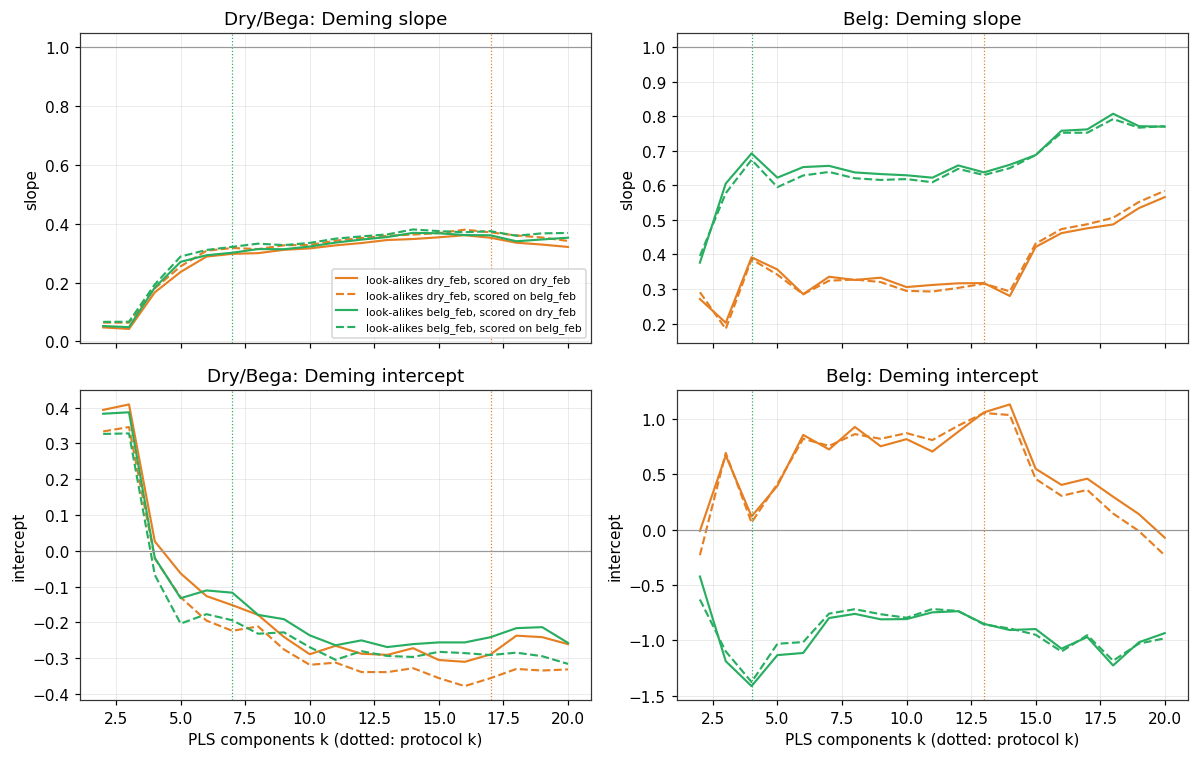

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for j, s in enumerate(['Dry/Bega', 'Belg']):
    for i, (val, ref) in enumerate([('slope', 1), ('intercept', 0)]):
        ax = axes[i, j]
        for c_set, col in zip(CAL, ['#E67E22', '#27AE60']):
            for score_cal, ls in zip(CAL, ['-', '--']):
                q = sweep[(sweep['look-alikes from'] == c_set) & (sweep['scored on'] == score_cal) & (sweep.season == s)]
                ax.plot(q.k, q[val], ls=ls, color=col, lw=1.4, label=f'look-alikes {c_set}, scored on {score_cal}')
            ax.axvline(look[c_set][2][s], color=col, lw=0.8, ls=':')
        ax.axhline(ref, color='#999', lw=0.8)
        ax.set_title(f'{s}: Deming {val}'); ax.set_ylabel(val)
        if i == 1: ax.set_xlabel('PLS components k (dotted: protocol k)')
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig('output/plots/addis_feb_sensitivity_k_sweep.png', bbox_inches='tight')
plt.show()

## 6. The 18 February filters themselves

In [11]:
feb = month == 2
rows = []
for cal_name, by in CALIBRATIONS.items():
    for c in CAL:
        y = by[c][feb]
        rows.append({'calibration': cal_name, 'calendar': c, 'February filters binned as': CAL[c][feb][0],
                     'n': int(feb.sum()), 'median FTIR/HIPS': float(np.median(y / hips[feb])),
                     'median error µg/m³': float(np.median(y - hips[feb]))})
feb_tab = pd.DataFrame(rows)
feb_tab.to_csv(OUT / 'february_filters.csv', index=False)
feb_tab.round(3)

,calibration,calendar,February filters binned as,n,median FTIR/HIPS,median error µg/m³
0,season-specific look-alikes (Figure 9),dry_feb,Dry/Bega,18,0.266,-3.160
1,season-specific look-alikes (Figure 9),belg_feb,Belg,18,0.318,-2.893
2,SPARTAN published,dry_feb,Dry/Bega,18,0.747,-1.148
3,SPARTAN published,belg_feb,Belg,18,0.747,-1.148
4,all IMPROVE (Figure 7),dry_feb,Dry/Bega,18,0.256,-3.207
5,all IMPROVE (Figure 7),belg_feb,Belg,18,0.256,-3.207
6,500 lowest TOR OC/EC,dry_feb,Dry/Bega,18,0.363,-2.491
7,500 lowest TOR OC/EC,belg_feb,Belg,18,0.363,-2.491


## 7. Does the organic-signal finding survive? (28 Oct item 2)

Within Dry and Belg, the Addis error tracked the organic band signal per µg EC (partial Spearman ρ, HIPS
EC's effect removed). Here is the same statistic under each calendar.

In [12]:
bands = rm.band_areas(d['XA'], d['wn']).div(vol, axis=0)
org = bands[rm.ORGANIC].rank(pct=True).mean(1).to_numpy()
rows = []
for cal_name in ('season-specific look-alikes (Figure 9)', 'all IMPROVE (Figure 7)'):
    for c, labels in CAL.items():
        for s in SEAS:
            m = labels == s
            y = CALIBRATIONS[cal_name][c]
            rows.append({'calibration': cal_name, 'calendar': c, 'season': s, 'n': int(m.sum()),
                         'partial ρ organic index': rm.partial_spearman(y[m], org[m], hips[m]),
                         'partial ρ C-H': rm.partial_spearman(y[m], bands['C-H 2800-3000'].to_numpy()[m], hips[m])})
organic = pd.DataFrame(rows)
organic.to_csv(OUT / 'organic_partial_rho.csv', index=False)
organic.pivot_table(index=['calibration', 'season'], columns='calendar',
                    values=['n', 'partial ρ organic index', 'partial ρ C-H'], sort=False).round(2)

n          partial ρ organic index          partial ρ C-H         
calendar                                        dry_feb belg_feb                 dry_feb belg_feb       dry_feb belg_feb
calibration                            season                                                                           
season-specific look-alikes (Figure 9) Dry/Bega    73.0     55.0                    0.46     0.53          0.46     0.52
                                       Belg        51.0     69.0                    0.63     0.13          0.64     0.18
                                       Kiremt      65.0     65.0                    0.09     0.09          0.01     0.01
all IMPROVE (Figure 7)                 Dry/Bega    73.0     55.0                    0.40     0.47          0.44     0.50
                                       Belg        51.0     69.0                    0.51     0.28          0.57     0.34
                                       Kiremt      65.0     65.0                    0.25     0.25          0.27     0.27

## 8. Figures

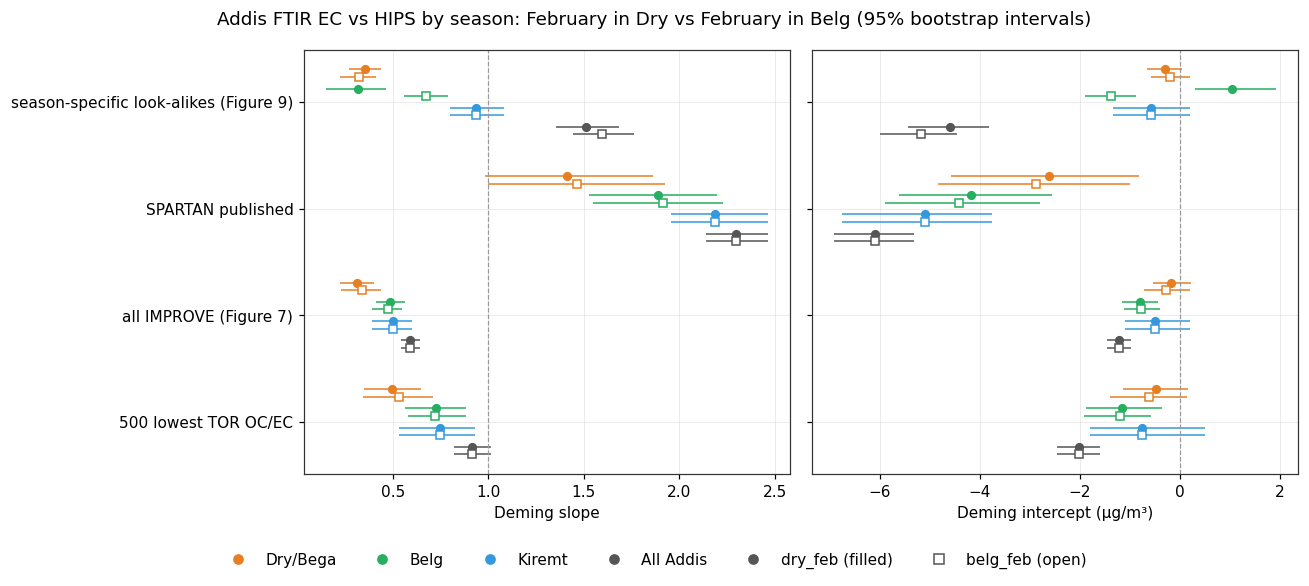

In [13]:
COL = {'Dry/Bega': '#E67E22', 'Belg': '#27AE60', 'Kiremt': '#3498DB', 'All Addis': '#555555'}
cals = list(CALIBRATIONS)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (val, lo, hi, ref, lab) in zip(axes, [('deming_slope', 'slope_ci_low', 'slope_ci_high', 1, 'Deming slope'),
                                              ('deming_intercept', 'intercept_ci_low', 'intercept_ci_high', 0, 'Deming intercept (µg/m³)')]):
    for i, cal_name in enumerate(cals):
        for j, s in enumerate(SEAS + ['All Addis']):
            for h, c in enumerate(CAL):
                r = stats[(stats.calibration == cal_name) & (stats.season == s) & (stats.calendar == c)].iloc[0]
                yv = i + (j - 1.5) * 0.18 + (h - 0.5) * 0.07
                ax.errorbar(r[val], yv, xerr=[[r[val] - r[lo]], [r[hi] - r[val]]], fmt='o' if c == 'dry_feb' else 's',
                            mfc=COL[s] if c == 'dry_feb' else 'white', mec=COL[s], ecolor=COL[s], ms=5, lw=1)
    ax.axvline(ref, color='#999', lw=0.8, ls='--')
    ax.set_yticks(range(len(cals)), cals)
    ax.invert_yaxis()
    ax.set_xlabel(lab)
axes[1].set_yticklabels([])
handles = [plt.Line2D([], [], marker='o', ls='', color=COL[s], label=s) for s in COL]
handles += [plt.Line2D([], [], marker='o', ls='', color='#555', label='dry_feb (filled)'),
            plt.Line2D([], [], marker='s', ls='', mfc='white', mec='#555', label='belg_feb (open)')]
fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Addis FTIR EC vs HIPS by season: February in Dry vs February in Belg (95% bootstrap intervals)')
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig('output/plots/addis_feb_sensitivity_coefficients.png', bbox_inches='tight')
plt.show()

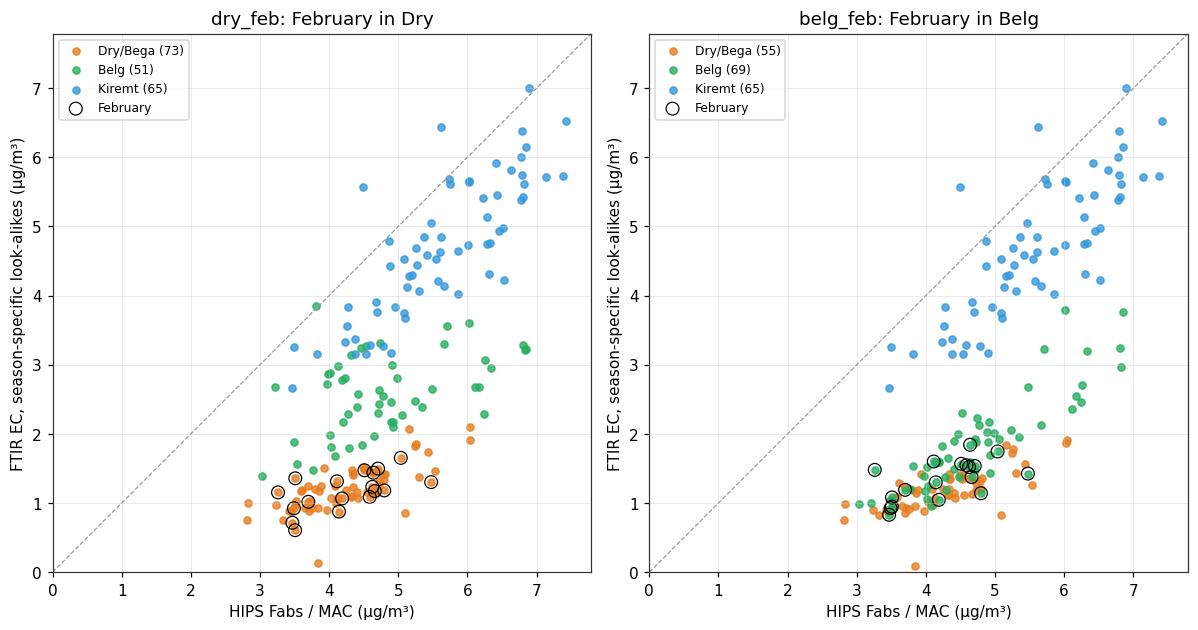

In [14]:
# Figure 9 predictions against HIPS, square panels, February filters ringed
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
lim = (0, float(np.nanmax([hips.max(), *(look[c][0].max() for c in CAL)])) * 1.05)
for ax, c in zip(axes, CAL):
    y = look[c][0]
    for s in SEAS:
        m = CAL[c] == s
        ax.scatter(hips[m], y[m], s=22, color=COL[s], alpha=0.8, label=f'{s} ({m.sum()})')
    ax.scatter(hips[feb], y[feb], s=70, facecolors='none', edgecolors='k', lw=0.8, label='February')
    ax.plot(lim, lim, color='#999', lw=0.8, ls='--')
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal')
    ax.set_xlabel('HIPS Fabs / MAC (µg/m³)'); ax.set_ylabel('FTIR EC, season-specific look-alikes (µg/m³)')
    ax.set_title(f'{c}: February in {"Dry" if c == "dry_feb" else "Belg"}')
    ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig('output/plots/addis_feb_sensitivity_figure9.png', bbox_inches='tight')
plt.show()